In [1]:
!pip install -q pandas numpy scikit-learn matplotlib seaborn

In [2]:
import pandas as pd
import numpy as np

from sklearn.datasets import fetch_openml

# Load dataset
titanic = fetch_openml(
    name="titanic",
    version=1,
    as_frame=True
)

df = titanic.frame

print("Dataset loaded successfully!")
print(df.head())
print(df.shape)

Dataset loaded successfully!
   pclass survived                                             name     sex  \
0       1        1                    Allen, Miss. Elisabeth Walton  female   
1       1        1                   Allison, Master. Hudson Trevor    male   
2       1        0                     Allison, Miss. Helen Loraine  female   
3       1        0             Allison, Mr. Hudson Joshua Creighton    male   
4       1        0  Allison, Mrs. Hudson J C (Bessie Waldo Daniels)  female   

       age  sibsp  parch  ticket      fare    cabin embarked boat   body  \
0  29.0000      0      0   24160  211.3375       B5        S    2    NaN   
1   0.9167      1      2  113781  151.5500  C22 C26        S   11    NaN   
2   2.0000      1      2  113781  151.5500  C22 C26        S  NaN    NaN   
3  30.0000      1      2  113781  151.5500  C22 C26        S  NaN  135.0   
4  25.0000      1      2  113781  151.5500  C22 C26        S  NaN    NaN   

                         home.dest  
0 

In [3]:
# Dataset information
print(df.info())

# Statistical summary
print(df.describe(include="all"))

# Missing values
print(df.isnull().sum())

# Duplicate rows
print("Duplicates:", df.duplicated().sum())

# Target distribution
print(df["survived"].value_counts())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1309 entries, 0 to 1308
Data columns (total 14 columns):
 #   Column     Non-Null Count  Dtype   
---  ------     --------------  -----   
 0   pclass     1309 non-null   int64   
 1   survived   1309 non-null   category
 2   name       1309 non-null   object  
 3   sex        1309 non-null   category
 4   age        1046 non-null   float64 
 5   sibsp      1309 non-null   int64   
 6   parch      1309 non-null   int64   
 7   ticket     1309 non-null   object  
 8   fare       1308 non-null   float64 
 9   cabin      295 non-null    object  
 10  embarked   1307 non-null   category
 11  boat       486 non-null    object  
 12  body       121 non-null    float64 
 13  home.dest  745 non-null    object  
dtypes: category(3), float64(3), int64(3), object(5)
memory usage: 116.8+ KB
None
             pclass survived              name   sex          age  \
count   1309.000000     1309              1309  1309  1046.000000   
unique          N

In [4]:
features = [
    "pclass",
    "sex",
    "age",
    "sibsp",
    "parch",
    "fare",
    "embarked"
]

X = df[features].copy()
y = pd.to_numeric(df["survived"], errors="coerce")

# Remove rows with missing target
valid = y.notna()

X = X.loc[valid]
y = y.loc[valid].astype(int)

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1309, 7)
Target shape: (1309,)


In [5]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1047, 7)
Testing data: (262, 7)


In [6]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

# Separate column types
numeric_features = [
    "pclass", "age", "sibsp", "parch", "fare"
]

categorical_features = [
    "sex", "embarked"
]

# Numerical preprocessing
numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Categorical preprocessing
categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Combine preprocessing
preprocessor = ColumnTransformer(transformers=[
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

print("Preprocessing pipeline created successfully!")

Preprocessing pipeline created successfully!


In [7]:
from sklearn.ensemble import RandomForestClassifier

model = Pipeline(steps=[
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=100,
        random_state=42,
        class_weight="balanced"
    ))
])

# Train model
model.fit(X_train, y_train)

print("Model trained successfully!")

Model trained successfully!


In [8]:
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Predictions
y_pred = model.predict(X_test)

# Accuracy
accuracy = accuracy_score(y_test, y_pred)

print("Model Accuracy:", accuracy)

# Classification report
print(classification_report(y_test, y_pred))

# Confusion matrix
print(confusion_matrix(y_test, y_pred))

Model Accuracy: 0.7938931297709924
              precision    recall  f1-score   support

           0       0.84      0.83      0.83       162
           1       0.73      0.74      0.73       100

    accuracy                           0.79       262
   macro avg       0.78      0.78      0.78       262
weighted avg       0.79      0.79      0.79       262

[[134  28]
 [ 26  74]]


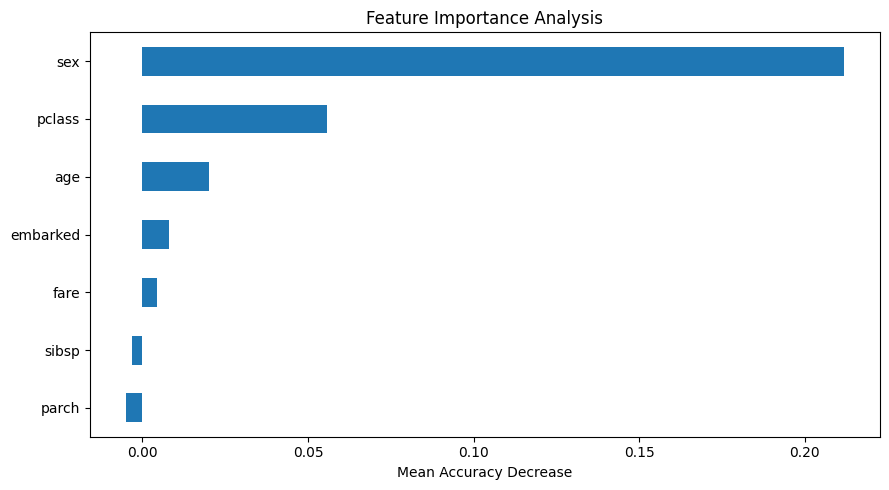

In [9]:
import matplotlib.pyplot as plt

from sklearn.inspection import permutation_importance

result = permutation_importance(
    model,
    X_test,
    y_test,
    n_repeats=10,
    random_state=42,
    scoring="accuracy"
)

importance = pd.Series(
    result.importances_mean,
    index=X_test.columns
).sort_values(ascending=True)

importance.plot(
    kind="barh",
    figsize=(9, 5)
)

plt.title("Feature Importance Analysis")
plt.xlabel("Mean Accuracy Decrease")
plt.tight_layout()
plt.show()